# NN_L4_fmnist_compare

**Test accuracy (mean and standard deviation over three seeds) and number of parameters of softmax regression, MLP and CNN on Fashion-MNIST.**

Neural Networks and Deep Learning (NN), Lecture 4 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/NEURAL_BIZ/blob/main/Quantlets/L4/NN_L4_fmnist_compare/NN_L4_fmnist_compare.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/'

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
# course chart style: transparent background, no gridlines, legend at the bottom outside the axes, four-digit years
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5, 'legend.frameon': False,
    'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
PAL = {'data': '#2a78d6', 'model': '#eb6834', 'benchmark': '#1baf7a', 'alt': '#eda100',
       'train': '#2a78d6', 'valid': '#eb6834', 'test': '#6250d6', 'positive': '#e34948', 'negative': '#2a78d6'}


def legend_bottom(fig, ncol=4):
    h, l_ = [], []
    for ax in fig.axes:
        for hh, ll in zip(*ax.get_legend_handles_labels()):
            if ll not in l_:
                h.append(hh); l_.append(ll)
    if h:
        fig.legend(h, l_, loc='lower center', ncol=min(ncol, len(h)), bbox_to_anchor=(0.5, 0.0), frameon=False)


def show(key, label, value):
    # print a number of the slide; [key] = its name in lectures/Lk/Lk_numbers.json
    print(f'{label} = {value}   [{key}]')

Accuracy and size of the three models; McNemar's test CNN vs MLP on the 10,000 test images (seed 20261108).

softmax: mean test accuracy (%) = 84.5   [fmnist.softmax.acc_mean]
softmax: sd = 0.06   [fmnist.softmax.acc_sd]
softmax: parameters = 7850   [fmnist.softmax.params]
mlp: mean test accuracy (%) = 89.0   [fmnist.mlp.acc_mean]
mlp: sd = 0.1   [fmnist.mlp.acc_sd]
mlp: parameters = 235146   [fmnist.mlp.params]
cnn: mean test accuracy (%) = 93.08   [fmnist.cnn.acc_mean]
cnn: sd = 0.2   [fmnist.cnn.acc_sd]
cnn: parameters = 140778   [fmnist.cnn.params]
right only for the CNN = 614   [fmnist.mcnemar.cnn_only]
right only for the MLP = 226   [fmnist.mcnemar.mlp_only]
McNemar chi2 = 178.3   [fmnist.mcnemar.chi2]


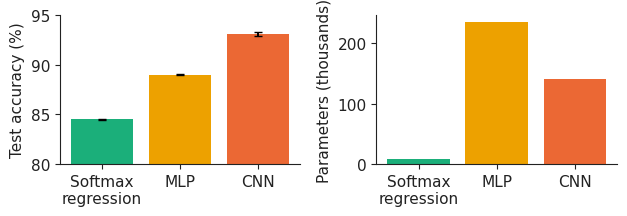

In [3]:
import json, urllib.request
_F = 'fmnist_compare_results.json'
R = json.load(open(_F)) if os.path.isfile(_F) else json.load(urllib.request.urlopen(REPO + 'Quantlets/L4/NN_L4_fmnist_compare/' + _F))
for k in ['softmax', 'mlp', 'cnn']:
    a = 100 * np.array(R[k]['acc'])
    show(f'fmnist.{k}.acc_mean', f'{k}: mean test accuracy (%)', round(float(a.mean()), 2)); show(f'fmnist.{k}.acc_sd', f'{k}: sd', round(float(a.std(ddof=1)), 2))
    show(f'fmnist.{k}.params', f'{k}: parameters', R[k]['params'])
y, pc, pm = np.array(R['y']), np.array(R['cnn_pred']), np.array(R['mlp_pred'])
b, c = int(((pc == y) & (pm != y)).sum()), int(((pc != y) & (pm == y)).sum())
show('fmnist.mcnemar.cnn_only', 'right only for the CNN', b); show('fmnist.mcnemar.mlp_only', 'right only for the MLP', c)
show('fmnist.mcnemar.chi2', 'McNemar chi2', round((abs(b - c) - 1) ** 2 / (b + c), 1))
fig, axes = plt.subplots(1, 2, figsize=(6.4, 2.3)); lab = ['Softmax\nregression', 'MLP', 'CNN']; cols = [PAL['benchmark'], PAL['alt'], PAL['model']]
acc = [100 * np.mean(R[k]['acc']) for k in ['softmax', 'mlp', 'cnn']]; sd = [100 * np.std(R[k]['acc'], ddof=1) for k in ['softmax', 'mlp', 'cnn']]
axes[0].bar(lab, acc, yerr=sd, color=cols, capsize=3); axes[0].set_ylim(80, 95); axes[0].set_ylabel('Test accuracy (%)')
axes[1].bar(lab, [R[k]['params'] / 1000 for k in ['softmax', 'mlp', 'cnn']], color=cols); axes[1].set_ylabel('Parameters (thousands)')
fig.tight_layout()
fig.savefig('fmnist_compare.png', dpi=200, transparent=True, bbox_inches='tight')
plt.show()